# Welcome to Colab!

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.neural_network import MLPRegressor

In [5]:
FILE = "/content/Indian Rainfall Dataset District-wise Daily Measurements.csv"
df = pd.read_csv(FILE, sep=None, engine="python")
df.columns = df.columns.str.strip()
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (8790, 34)


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
0,Andaman & Nicobar,Nicobars,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,Andaman & Nicobar,North And Middle Andaman,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,Andaman & Nicobar,South Andamans,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,Andhra Pradesh,Anantapur,1,0.379965,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.205834,0.671002,0.028994,0.0,0.0,0.0
4,Andhra Pradesh,Chittoor,1,14.144900,0.857263,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.615237,0.925098,0.507623,0.424843,0.737394,0.0,0.0,0.0


MAE: 3.366858764861296
RMSE: 8.228599706870252


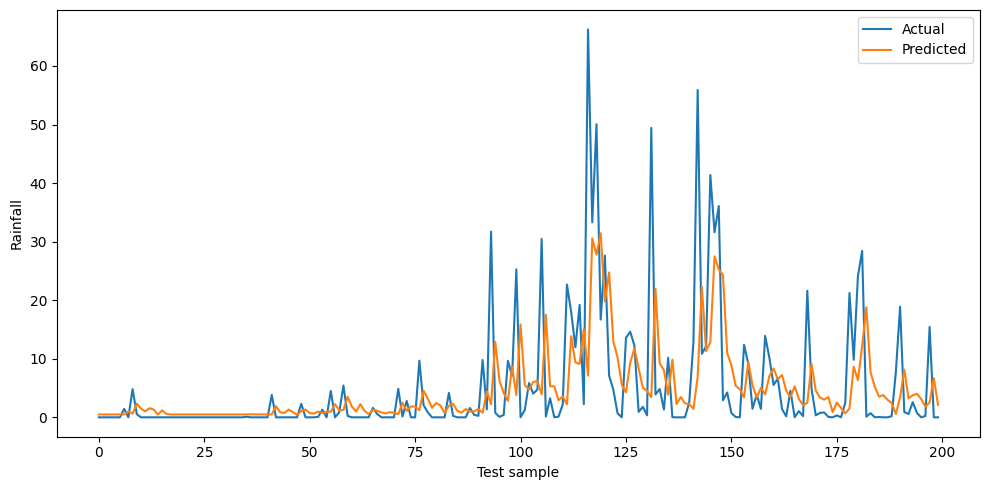

In [7]:
# Identify daily rainfall columns using ordinal patterns (e.g., '1st', '2nd', ..., '31st')
import re
def is_ordinal_day(col):
    # Match strings ending in 'st', 'nd', 'rd', 'th' preceded by numbers 1-31
    match = re.match(r'^(\d+)(st|nd|rd|th)$', col.lower())
    if match:
        val = int(match.group(1))
        return 1 <= val <= 31
    return False

days = [c for c in df.columns if is_ordinal_day(c)]
if not days:
    days = [c for c in df.columns if c.lower().startswith("day")]
if not days:
    days = [c for c in df.columns if c.isdigit() and 1 <= int(c) <= 31]
if not days:
    raise ValueError(f"Daily columns not found. Check your CSV column names. Available columns: {list(df.columns)}")

district_col = next((c for c in df.columns if "district" in c.lower()), None)
records = []
for _, row in df.iterrows():
    district = str(row[district_col]) if district_col else "All"
    values = pd.to_numeric(row[days], errors="coerce").to_numpy(float)
    for day, rain in enumerate(values, 1):
        if np.isfinite(rain):
            records.append((district, day, max(0, rain)))

daily = pd.DataFrame(records, columns=["District", "Day", "Rainfall"])
daily["Rainfall"] = daily.groupby("District")["Rainfall"].transform(
    lambda x: x.fillna(x.median())
).fillna(0)

# Seven previous measurements predict the next measurement
X, y, groups = [], [], []
for district, part in daily.groupby("District", sort=False):
    a = part["Rainfall"].to_numpy()
    for i in range(7, len(a)):
        X.append(a[i-7:i])
        y.append(a[i])
        groups.append(district)

X, y = np.array(X), np.array(y)
if len(X) < 10:
    raise ValueError("Not enough daily measurements to train the model.")

# Chronological 80/20 split
cut = int(len(X) * 0.8)
X_train, X_test = X[:cut], X[cut:]
y_train, y_test = y[:cut], y[cut:]

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = MLPRegressor(hidden_layer_sizes=(64, 32),
                     max_iter=300, early_stopping=True,
                     random_state=42)
model.fit(X_train, y_train)
pred = np.maximum(0, model.predict(X_test))

print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

results = pd.DataFrame({
    **{f"Previous_Day_{i}": X[cut:, i-1] for i in range(1, 8)},
    "Actual_Rainfall": y_test,
    "Predicted_Rainfall": pred,
    "Absolute_Error": np.abs(y_test - pred)
})
results.to_csv("Rainfall_Predictions.csv", index=False)

plt.figure(figsize=(10, 5))
plt.plot(y_test[:200], label="Actual")
plt.plot(pred[:200], label="Predicted")
plt.xlabel("Test sample")
plt.ylabel("Rainfall")
plt.legend()
plt.tight_layout()
plt.savefig("Rainfall_Actual_vs_Predicted.png")
plt.show()

### Step 1: Time Series Construction & Sequential Target Extraction

In [8]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Group the sequential records daily for each district
daily_sorted = daily.sort_values(by=['District', 'Day']).reset_index(drop=True)

# Construct sequences where the past 7 days of rainfall predict the 8th day
X, y, dates = [], [], []

for district, grp in daily_sorted.groupby('District'):
    rain_vals = grp['Rainfall'].to_numpy()
    days_seq = grp['Day'].to_numpy()
    for i in range(7, len(rain_vals)):
        X.append(rain_vals[i-7:i])
        y.append(rain_vals[i])
        # Synthesize a relative step date marker representing the predicted day
        dates.append(f"{district}_Day_{days_seq[i]}")

X = np.array(X)
y = np.array(y)
dates = np.array(dates)

print(f"Generated {len(X)} sequence samples with shape: {X.shape}")

Generated 266512 sequence samples with shape: (266512, 7)


### Step 2: Model Selection and Justification
We select the **MLPRegressor (Multi-Layer Perceptron)** for the following reasons:
1. **Non-linear mapping**: Daily rainfall patterns are highly non-linear and sensitive; feed-forward deep neural network structures capture complex interactions between consecutive lag days much better than traditional linear autoregressive (AR) models.
2. **Fixed-lag Temporal Modeling**: Using a fixed lag sequence ($t-7$ to $t-1$) fits MLP architectures perfectly without requiring recurrence calculations, avoiding vanishing gradient issues commonly found in RNNs during basic steps.

### Step 3: Chronological Train/Test Split & Neural Network Training

In [9]:
from sklearn.neural_network import MLPRegressor

# 80/20 chronological split to avoid data leakage from future sequence trends
split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
test_dates = dates[split_idx:]

# Normalize the sequential feature space
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the neural network regressor
model = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=42)
model.fit(X_train_scaled, y_train)
print("Model training finished successfully.")

Model training finished successfully.


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


### Step 4: Metric Evaluation (MAE & RMSE) and Comparison Plotting

Mean Absolute Error (MAE): 4.8697 mm
Root Mean Squared Error (RMSE): 13.1600 mm


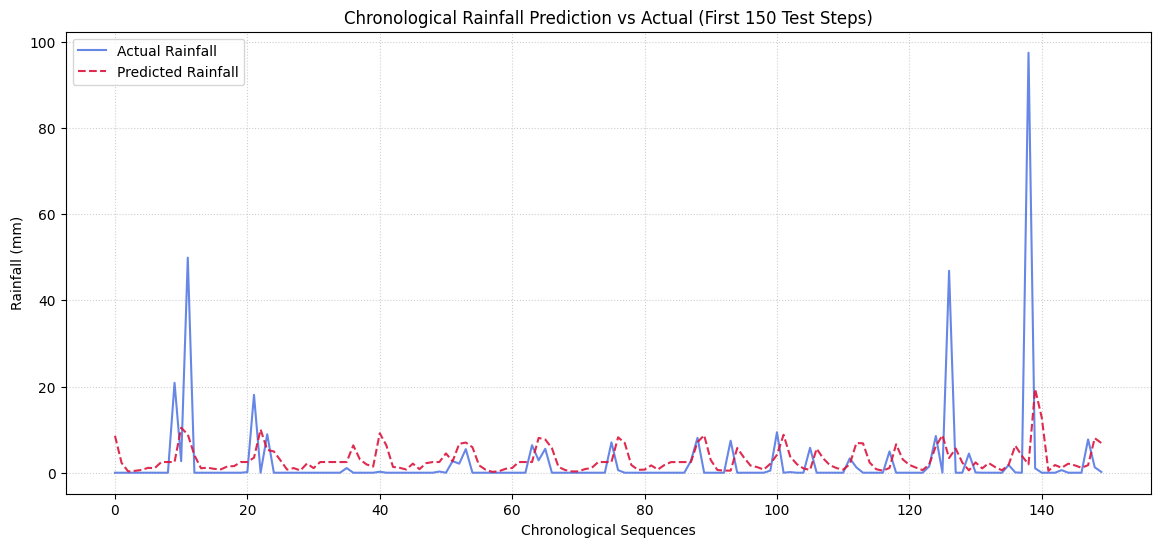

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# Generate predictions
predictions = np.maximum(0, model.predict(X_test_scaled))

# Calculate metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
print(f"Mean Absolute Error (MAE): {mae:.4f} mm")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} mm")

# Plot Actual vs Predicted Rainfall
plt.figure(figsize=(14, 6))
plt.plot(y_test[:150], label="Actual Rainfall", color="royalblue", alpha=0.8, linewidth=1.5)
plt.plot(predictions[:150], label="Predicted Rainfall", color="crimson", linestyle="--", alpha=0.9, linewidth=1.5)
plt.title("Chronological Rainfall Prediction vs Actual (First 150 Test Steps)")
plt.xlabel("Chronological Sequences")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

### Step 5: Demonstration on Unseen Dates / Sequences
We feed a completely new/unseen rainfall sequence to make future next-step predictions.

In [11]:
# Synthesize an unseen input sequence representing the last 7 days of rainfall
unseen_rainfall_sequence = np.array([[12.5, 0.0, 4.2, 18.9, 25.1, 8.0, 1.2]])

# Transform using fitted MinMaxScaler
unseen_scaled = scaler.transform(unseen_rainfall_sequence)

# Predict next day rainfall
predicted_value = np.maximum(0, model.predict(unseen_scaled))[0]
print(f"Input Rainfall Sequence (Past 7 Days): {unseen_rainfall_sequence[0]}")
print(f"Predicted Rainfall for Next Day: {predicted_value:.4f} mm")

Input Rainfall Sequence (Past 7 Days): [12.5  0.   4.2 18.9 25.1  8.   1.2]
Predicted Rainfall for Next Day: 2.8551 mm


### Step 6: Define and Train an LSTM Sequence Learning Model

We will use an LSTM (Long Short-Term Memory) network which is inherently suited for sequential time series data. We reshape our inputs into the required 3D format `[samples, timesteps, features]`, configure the architecture with TensorFlow, and train it for exactly 10 epochs.

In [12]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input

# Reshape input data to 3D tensor: [samples, timesteps, features]
# Our sequence has 7 timesteps and 1 feature (daily rainfall)
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))

# Define the LSTM architecture
lstm_model = Sequential([
    Input(shape=(7, 1)),
    LSTM(32, return_sequences=False),
    Dense(16, activation='relu'),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse')

# Train the model for exactly 10 epochs
history = lstm_model.fit(
    X_train_lstm, y_train,
    epochs=10,
    batch_size=256,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 106.6435 - val_loss: 82.6155
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 105.1628 - val_loss: 82.2493
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 104.1815 - val_loss: 81.0795
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 101.3875 - val_loss: 79.2321
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 99.7496 - val_loss: 78.7946
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 99.1593 - val_loss: 79.1766
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 98.9734 - val_loss: 78.6514
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 98.8321 - val_loss: 78.9605
Epoch 9/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 98.7319 - val_loss: 78.7418
Epoch 10/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 98.5561 - val_loss: 78.4224


### Step 7: Evaluate LSTM Performance using MAE and RMSE

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Generate model predictions and ensure no negative rainfall values are outputted
lstm_pred = np.maximum(0, lstm_model.predict(X_test_lstm).flatten())

# Calculate metrics
lstm_mae = mean_absolute_error(y_test, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_test, lstm_pred))

print(f"LSTM Mean Absolute Error (MAE): {lstm_mae:.4f} mm")
print(f"LSTM Root Mean Squared Error (RMSE): {lstm_rmse:.4f} mm")

1666/1666 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
LSTM Mean Absolute Error (MAE): 5.0852 mm
LSTM Root Mean Squared Error (RMSE): 13.4489 mm


### Step 8: Visualizing LSTM Actual vs Predicted Rainfall

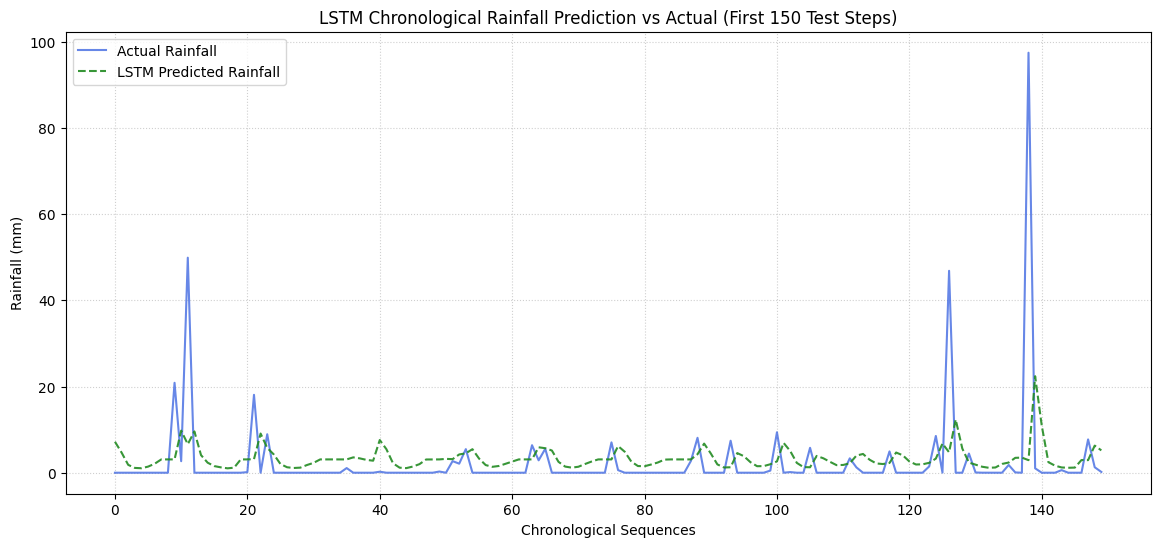

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(y_test[:150], label="Actual Rainfall", color="royalblue", alpha=0.8, linewidth=1.5)
plt.plot(lstm_pred[:150], label="LSTM Predicted Rainfall", color="forestgreen", linestyle="--", alpha=0.9, linewidth=1.5)
plt.title("LSTM Chronological Rainfall Prediction vs Actual (First 150 Test Steps)")
plt.xlabel("Chronological Sequences")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

### Step 9: LSTM Prediction Demonstration for Unseen Sequences

In [15]:
# Take the unseen sequence from earlier, scale, and reshape for LSTM prediction
unseen_scaled_lstm = unseen_scaled.reshape((unseen_scaled.shape[0], unseen_scaled.shape[1], 1))

lstm_future_pred = np.maximum(0, lstm_model.predict(unseen_scaled_lstm))[0][0]
print(f"Input Rainfall Sequence (Past 7 Days): {unseen_rainfall_sequence[0]}")
print(f"LSTM Predicted Rainfall for Next Day: {lstm_future_pred:.4f} mm")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Input Rainfall Sequence (Past 7 Days): [12.5  0.   4.2 18.9 25.1  8.   1.2]
LSTM Predicted Rainfall for Next Day: 2.5860 mm
